# 12 · Kerr cats, cubic phases and the quantics Fourier transform

1. **Yurke & Stoler**, *PRL* **57**, 13 (1986): a Kerr medium turns a coherent state into a
   superposition of coherent states, $e^{-i\pi n^2/2}|\alpha\rangle=(e^{-i\pi/4}|\alpha\rangle+e^{i\pi/4}|{-\alpha}\rangle)/\sqrt2$. The
   quantics rank of the evolving state stays small (as in the paper's Fig. 5).
2. **Chen, Stoudenmire & White**, *PRX Quantum* **4**, 040318 (2023): the quantum Fourier transform
   has small rank as an MPO — *without* the final bit reversal.
3. The design measurements behind the CV extension: ladder operators in position space have flat rank; a cubic
   phase *operator* is high-rank but the *state* it produces is not.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tutorial_utils as tu
from tutorial_utils import cd, dr

print(tu.cv_banner())
if tu.HAVE_CV:
    from qttlind.cv import QuadratureGrid, grids as gr, fourier as fo, operators as op, gates as ga
    from qttlind.bosons import states as bs
checks = {}

qttlind 2.0.0 -- gaussian backend: yes; quantics CV: yes; circuits: yes.


## 1. Kerr evolution: ranks and the Yurke–Stoler cat

$U(t)=e^{-iKtn^2}$ is diagonal in Fock space. We follow $|\alpha=2\rangle$ on $2^7$ Fock states and record
the quantics rank of $e^{-iKtn^2}|\alpha\rangle$, and of the phase $e^{-iKtn^2}$ itself.

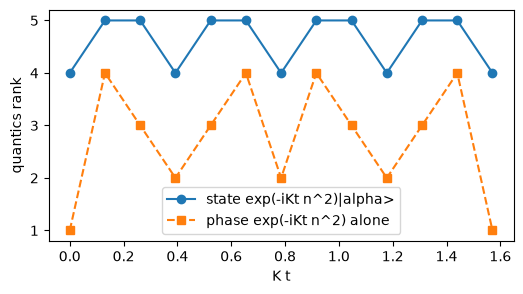

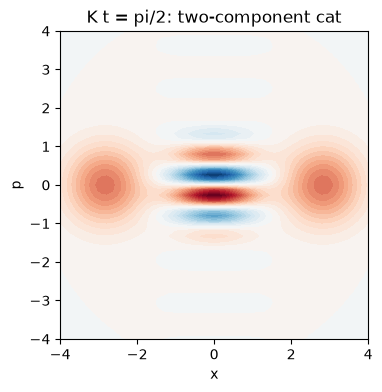

In [2]:
R, alpha = 7, 2.0
n = np.arange(2**R)
psi0 = dr.coherent(2**R, alpha)
times = np.linspace(0, np.pi / 2, 13)                # K t
state_rank, phase_rank = [], []
for kt in times:
    ph = np.exp(-1j * kt * n**2)
    if tu.HAVE_CV:
        state_rank.append(ga.kerr(bs.coherent(alpha, R), -kt, tol=1e-20).max_rank)
    else:
        state_rank.append(max(tu.tt_ranks(tu.tt_svd(ph * psi0, R, tol=1e-20))))
    phase_rank.append(max(tu.tt_ranks(tu.tt_svd(ph, R, tol=1e-20))))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(times, state_rank, "o-", label="state exp(-iKt n^2)|alpha>")
ax.plot(times, phase_rank, "s--", label="phase exp(-iKt n^2) alone")
ax.set_xlabel("K t"); ax.set_ylabel("quantics rank"); ax.legend(); tu.savefig(fig, "12_kerr_ranks.png")

cat = np.exp(-1j * np.pi / 2 * n**2) * psi0
target = (np.exp(-1j * np.pi / 4) * dr.coherent(2**R, alpha) + np.exp(1j * np.pi / 4) * dr.coherent(2**R, -alpha)) / np.sqrt(2)
checks["Yurke-Stoler cat at K t = pi/2"] = (abs(1 - abs(np.vdot(target, cat))), 1e-10)
rho = np.outer(cat[:40], cat[:40].conj())
g = np.linspace(-4, 4, 61)
W = cd.wigner_parity(rho, (g[None, :] + 1j * g[:, None]) / np.sqrt(2)) / 2
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.contourf(g, g, W, 41, cmap="RdBu_r", vmin=-np.abs(W).max(), vmax=np.abs(W).max())
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("p"); ax.set_title("K t = pi/2: two-component cat")
tu.savefig(fig, "12_kerr_cat.png");

## 2. The quantics Fourier transform

Dense MPO ranks (TT-SVD of the interleaved matrix) for small $R$, and the package's
`dft_mpo` (built by Hadamard products of rank-2 factors) up to $R=24$.

dense ranks with / without reversal: [16, 16, 64, 64, 256, 256] [4, 4, 8, 8, 11, 11]


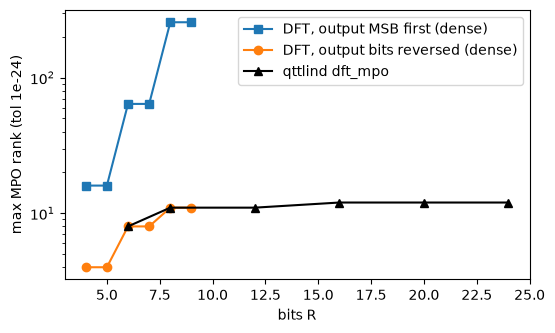

In [3]:
def centred_dft(R):
    N = 2**R; j = np.arange(N)
    return np.exp(-2j * np.pi * np.outer(j - N / 2, j - N / 2) / N) / np.sqrt(N)

def bitrev(R):
    return np.array([int(format(k, f"0{R}b")[::-1], 2) for k in range(2**R)])

Rs_dense = [4, 5, 6, 7, 8, 9]
with_rev, without_rev = [], []
for R in Rs_dense:
    F = centred_dft(R)
    with_rev.append(max(tu.tt_ranks(tu.matrix_to_qtt_mpo(F, R, tol=1e-24))))
    without_rev.append(max(tu.tt_ranks(tu.matrix_to_qtt_mpo(F[bitrev(R)], R, tol=1e-24))))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(Rs_dense, with_rev, "s-", label="DFT, output MSB first (dense)")
ax.semilogy(Rs_dense, without_rev, "o-", label="DFT, output bits reversed (dense)")
if tu.HAVE_CV:
    Rs = [6, 8, 12, 16, 20, 24]
    ranks = [fo.dft_mpo(R).max_rank for R in Rs]
    ax.semilogy(Rs, ranks, "k^-", label="qttlind dft_mpo")
    checks["dft_mpo vs dense (R = 8)"] = (np.abs(fo.dft_mpo(8).to_dense() - centred_dft(8)[bitrev(8)]).max(), 1e-12)
    checks["dft_mpo rank flat up to R = 24"] = (max(0, ranks[-1] - 16), 0)
ax.set_xlabel("bits R"); ax.set_ylabel("max MPO rank (tol 1e-24)"); ax.legend(); tu.savefig(fig, "12_fourier_ranks.png")
print("dense ranks with / without reversal:", with_rev, without_rev)

## 3. Operators in position space

$x$ is rank 2; $p=F^\dagger\,\mathrm{diag}(p)F$, $a$ and $n$ stay around 15 whatever the grid. This is
what lets the Lindblad solver run with modes in position space.

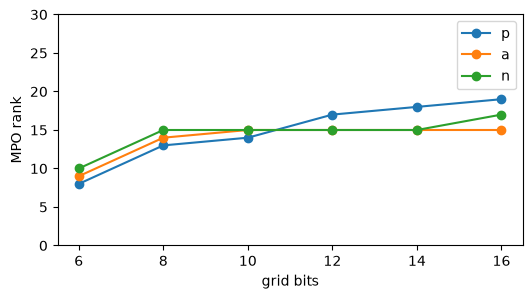

In [4]:
if tu.HAVE_CV:
    Rs = [6, 8, 10, 12, 14, 16]
    rk = {name: [] for name in ("p", "a", "n")}
    for R in Rs:
        g = QuadratureGrid(R)
        rk["p"].append(op.momentum(g).max_rank); rk["a"].append(op.annihilation(g).max_rank); rk["n"].append(op.number(g).max_rank)
    fig, ax = plt.subplots(figsize=(6, 3))
    for name, v in rk.items():
        ax.plot(Rs, v, "o-", label=name)
    ax.set_xlabel("grid bits"); ax.set_ylabel("MPO rank"); ax.set_ylim(0, 30); ax.legend(); tu.savefig(fig, "12_operator_ranks.png")
    g = QuadratureGrid(10)
    phi = gr.fock(7, g, tol=1e-28)
    checks["F phi_7 = (-i)^7 phi_7"] = ((fo.to_momentum(phi) - phi * (-1j) ** 7).compress(0.0)[0].norm(), 1e-9)
else:
    print("qttlind.cv is not available: operator ranks skipped.")

## 4. The cubic phase gate: operator rank versus state rank

$V(\gamma)=e^{i\gamma x^3/3}$ is the canonical non-Gaussian resource. Over the whole box the phase
oscillates wildly and its quantics rank grows like $2^{R/2}$; applied to a squeezed state it gives a
state of rank ~10. Hence D17: multiply the state, never build the operator. (The input is squeezed
in $p$, i.e. wide in $x$, so that $p\mapsto p+\gamma x^2$ bends it strongly enough to make $W$ negative.)

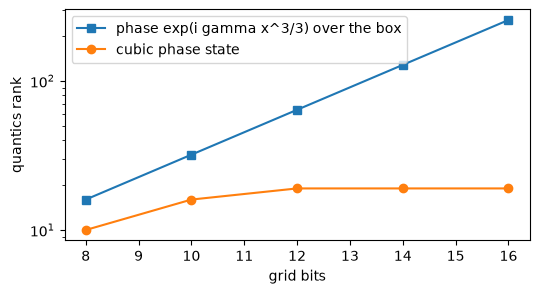

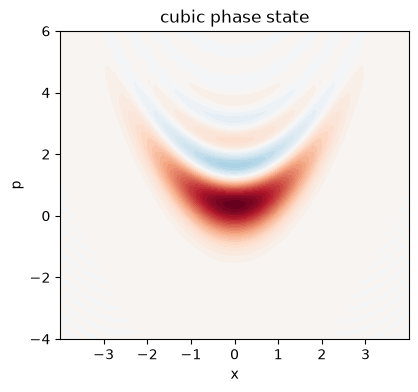

In [5]:
gamma, r = 0.5, -0.5   # r < 0: squeezed in p, wide in x -- the cubic phase bends it into a banana
Rs = [8, 10, 12, 14, 16]
op_rank, st_rank = [], []
for R in Rs:
    N = 2**R; dx = np.sqrt(2 * np.pi / N); x = (np.arange(N) - N / 2) * dx
    phase = np.exp(1j * gamma * x**3 / 3)
    op_rank.append(max(tu.tt_ranks(tu.tt_svd(phase, R, tol=1e-20))))
    if tu.HAVE_CV:
        g = QuadratureGrid(R)
        st_rank.append(ga.cubic_phase(gr.squeezed_vacuum(r, g), gamma, g).max_rank)
    else:
        sq = np.exp(-np.exp(2 * r) * x**2 / 2); sq /= np.linalg.norm(sq)
        st_rank.append(max(tu.tt_ranks(tu.tt_svd(phase * sq, R, tol=1e-20))))
fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogy(Rs, op_rank, "s-", label="phase exp(i gamma x^3/3) over the box")
ax.semilogy(Rs, st_rank, "o-", label="cubic phase state")
ax.set_xlabel("grid bits"); ax.set_ylabel("quantics rank"); ax.legend(); tu.savefig(fig, "12_cubic_ranks.png")

R = 10; N = 2**R; dx = np.sqrt(2 * np.pi / N); x = (np.arange(N) - N / 2) * dx
psi = np.exp(-np.exp(2 * r) * x**2 / 2) * np.exp(1j * gamma * x**3 / 3); psi /= np.sqrt(np.sum(np.abs(psi)**2) * dx)
xs = x[(x > -4) & (x < 4)][::2]; ps = np.linspace(-4, 6, 101)
W = tu.wigner_from_wavefunction(psi, x, ps, xs)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.contourf(xs, ps, W, 41, cmap="RdBu_r", vmin=-np.abs(W).max(), vmax=np.abs(W).max())
ax.set_xlabel("x"); ax.set_ylabel("p"); ax.set_title("cubic phase state"); tu.savefig(fig, "12_cubic_wigner.png")
checks["cubic phase state has Wigner negativity"] = (max(0.0, W.min() + 1e-3), 0.0)

## Acceptance table

In [6]:
for name, (dev, tol) in checks.items():
    print(f"{'ok ' if dev <= tol else 'FAIL'} {name:<52s} deviation {dev:9.2e}  (tolerance {tol:.0e})")
assert all(dev <= tol for dev, tol in checks.values()), "a benchmark is outside its tolerance"

ok  Yurke-Stoler cat at K t = pi/2                       deviation  2.22e-16  (tolerance 1e-10)
ok  dft_mpo vs dense (R = 8)                             deviation  2.54e-14  (tolerance 1e-12)
ok  dft_mpo rank flat up to R = 24                       deviation  0.00e+00  (tolerance 0e+00)
ok  F phi_7 = (-i)^7 phi_7                               deviation  5.24e-13  (tolerance 1e-09)
ok  cubic phase state has Wigner negativity              deviation  0.00e+00  (tolerance 0e+00)
